# 01 – Portafolio
**Lab #2 – Derivados Financieros** · Puntos 1 a 5 (proceso de creación del portafolio: 20 % + R5 y R6)

## Importar librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import yfinance as yf

RAW = Path("../data/raw")
PROC = Path("../data/processed")

## Punto 1 – Análisis fundamental (R1 – 5 %)

**Cabe aclarar que las acciones seleccionadas se eligieron por decisiones de los integrantes del grupo de forma aleatoria sin tener en cuenta análisis fundamental. Sin embargo, a continuación se realiza el análisis fundamental de por qué no cambiamos tales acciones.**

,Precio 30/10/2026,Máx 52s,Mín 52s,Dist. al máx,Ret. precio YTD,Ret. total 1a,Ret. total 3a,Ret. total 5a
ADI,417.11,445.48,225.20,-6.4%,53.8%,81.3%,180.4%,161.4%
CSCO,104.51,130.00,71.04,-19.6%,35.7%,46.0%,118.6%,114.1%
PYPL,57.01,69.27,39.08,-17.7%,-2.3%,-15.1%,12.9%,-75.2%
^NDX,"28,384.85","31,224.47","22,953.38",-9.1%,12.4%,10.3%,98.0%,79.1%


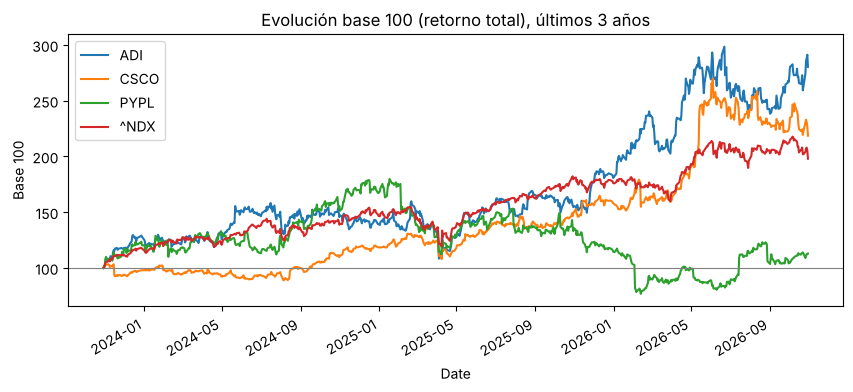

In [2]:
def leer_precios(nombre):
    df = pd.read_csv(RAW / nombre, index_col=0)                    # lee el CSV con la fecha como índice
    df = df[pd.to_datetime(df.index, errors="coerce").notna()]    # descarta filas de encabezado extra que deja yfinance
    df.index = pd.to_datetime(df.index)                           # convierte el índice a fechas
    return df.astype(float)                                       # asegura que los precios sean numéricos

close = leer_precios("close_diario.csv")      # precios sin ajustar (retorno de precio)
adj = leer_precios("adjclose_diario.csv")     # precios ajustados (retorno total)
f = close.index[-1]                           # fecha de inicio de la inversión: 30/10/2026

def ret(df, años):                                        # retorno entre hace N años y hoy
    p0 = df.loc[:f - pd.DateOffset(years=años)].iloc[-1]  # último precio disponible hace N años
    return df.iloc[-1] / p0 - 1                           # Pₜ / P₀ − 1

ult_año = close.loc[f - pd.DateOffset(years=1):]          # ventana de 52 semanas
evol = pd.DataFrame({
    "Precio 30/10/2026": close.iloc[-1],
    "Máx 52s": ult_año.max(),
    "Mín 52s": ult_año.min(),
    "Dist. al máx": close.iloc[-1] / ult_año.max() - 1,             # % por debajo del máximo
    "Ret. precio YTD": close.iloc[-1] / close.loc[:"2025-12-31"].iloc[-1] - 1,
    "Ret. total 1a": ret(adj, 1),
    "Ret. total 3a": ret(adj, 3),
    "Ret. total 5a": ret(adj, 5),
})
display(evol.style.format({"Precio 30/10/2026": "{:,.2f}", "Máx 52s": "{:,.2f}",
                           "Mín 52s": "{:,.2f}"}, precision=2).format(
        "{:.1%}", subset=evol.columns[3:]))                       # tabla con formato

base100 = adj.loc[f - pd.DateOffset(years=3):]                    # últimos 3 años
(base100 / base100.iloc[0] * 100).plot(figsize=(10, 4),
        title="Evolución base 100 (retorno total), últimos 3 años")
plt.axhline(100, color="grey", lw=0.8); plt.ylabel("Base 100"); plt.show()

### **Análisis evolución del precio:** 
Al analizar la evolución del precio, ADI y CSCO superaron al Nasdaq-100 en los tres periodos medidos. ADI rindió 81.3 % en un año, 180.4 % en tres y 161.4 % en cinco, frente a 10.3 %, 98.0 % y 79.1 % del índice. CSCO obtuvo 46.0 %, 118.6 % y 114.1 %. PYPL quedó por debajo en todos los plazos: −15.1 % a un año, 12.9 % a tres y −75.2 % a cinco. El gráfico muestra, que entre finales de 2024 y comienzos de 2025 PYPL estuvo por encima del índice, antes de una caída sostenida que la llevó a ser la única con retorno anual negativo.

In [3]:
acciones = ["CSCO", "ADI", "PYPL"]
campos = {                                       # campo de Yahoo: (nombre en la tabla, formato)
    "sector": ("Sector", "txt"), "industry": ("Industria", "txt"),
    "marketCap": ("Cap. bursátil (USD M)", "usd"), "totalRevenue": ("Ingresos 12m (USD M)", "usd"),
    "revenueGrowth": ("Crec. ingresos a/a", "pct"), "grossMargins": ("Margen bruto", "pct"),
    "operatingMargins": ("Margen operativo", "pct"), "profitMargins": ("Margen neto", "pct"),
    "returnOnEquity": ("ROE", "pct"), "freeCashflow": ("Flujo de caja libre 12m (USD M)", "usd"),
    "totalCash": ("Caja (USD M)", "usd"), "totalDebt": ("Deuda (USD M)", "usd"),
    "currentRatio": ("Razón corriente", "num"), "dividendRate": ("Dividendo anual (USD)", "num"),
}
precio = close.iloc[-1][acciones]                                     # precio al 30/10/2026
ARCH_FUND = PROC / "fundamentales_yahoo.csv"
FECHA_CONSULTA = "2026-11-01"                    # fecha de la foto de Yahoo usada en el laboratorio
if ARCH_FUND.exists():                           # reproducibilidad: se lee la foto guardada, no se re-consulta Yahoo
    fund = pd.read_csv(ARCH_FUND, index_col=0)
else:                                            # solo si no existe el CSV: consulta Yahoo y guarda la foto
    info = {t: yf.Ticker(t).info for t in acciones}
    fund = pd.DataFrame({t: {k: info[t].get(k) for k in campos} for t in acciones})
    num = lambda k: pd.to_numeric(fund.loc[k], errors="coerce")       # convierte una fila a número
    fund.loc["netCash"] = num("totalCash") - num("totalDebt")         # > 0: más caja que deuda
    fund.loc["divYield"] = num("dividendRate") / precio               # dividendo anual / precio
    fund.to_csv(ARCH_FUND)
    FECHA_CONSULTA = str(pd.Timestamp.today().date())
campos.update({"netCash": ("Caja neta (USD M)", "usd"), "divYield": ("Rend. dividendo", "pct")})

def fmt(v, tipo):                                 # formato: miles con coma y decimales con punto
    if v is None or (not isinstance(v, str) and pd.isna(v)): return "–"
    if tipo == "usd": return f"{float(v)/1e6:,.0f}"                  # millones de USD: 63,300
    if tipo == "pct": return f"{float(v):.1%}"                       # porcentaje: 16.3%
    if tipo == "num": return f"{float(v):,.2f}"                      # número: 1,234.56
    return v                                                          # texto (sector, industria)

tabla_12 = pd.DataFrame({t: [fmt(fund.at[k, t], f) for k, (_, f) in campos.items()] for t in acciones},
                        index=[n for n, _ in campos.values()])
print(f"{'=' * 82}\n{'SITUACIÓN FINANCIERA':^82}\n{'=' * 82}\nFuente: Yahoo Finance, consultado el {FECHA_CONSULTA}")
display(tabla_12)

                               SITUACIÓN FINANCIERA                               
Fuente: Yahoo Finance, consultado el 2026-11-01


,CSCO,ADI,PYPL
Sector,Technology,Technology,Financial Services
Industria,Communication Equipment,Semiconductors,Credit Services
Cap. bursátil (USD M),"412,040","202,117","47,356"
Ingresos 12m (USD M),"63,325","13,882","34,295"
Crec. ingresos a/a,17.6%,39.6%,2.0%
Margen bruto,64.5%,65.8%,40.5%
Margen operativo,27.7%,39.5%,18.4%
Margen neto,21.0%,29.8%,13.8%
ROE,27.3%,12.2%,23.8%
Flujo de caja libre 12m (USD M),"11,183","4,147","4,487"


### **Tabla de análisis fundamental**

| Elemento | CSCO – Cisco Systems | ADI – Analog Devices | PYPL – PayPal |
|---|---|---|---|
| **Descripción** | Líder mundial en equipos de redes y ciberseguridad.| Fabricante de chips que conectan el mundo físico con el digital.| Plataforma de pagos digitales (PayPal, Venmo, Braintree).|
| **Sector** | Tecnología · Equipos de comunicación | Tecnología · Semiconductores | Servicios financieros · Servicios de crédito (en la práctica, pagos digitales) |
| **Fuentes de ingresos** | Más de la mitad de lo que vende son los equipos que conectan las redes de empresas y centros de datos. El resto viene de ciberseguridad, herramientas de colaboración y contratos de soporte, que le dan ingresos estables año tras año. | Vende chips que convierten temperatura, sonido, energía o movimiento en datos. Casi la mitad de sus ventas va a la industria (fábricas, defensa, equipos de medición); el resto, a carros, centros de datos y electrónica de consumo. | Cobra una pequeña comisión por cada pago que procesa: eso es el 90 % de sus ingresos. El 10 % restante viene de créditos a consumidores e intereses sobre el dinero que los clientes dejan en sus cuentas. |
| **Evolución del precio** | +46.0 % en un año, pero 19.6 % por debajo de su máximo: subió con los pedidos de IA (may-2026) y cayó 9 % tras resultados (ago-2026) por temor a menor crecimiento. | +81.3 % en un año y cerca de su máximo (−6.4 %), impulsada por la recuperación industrial y la demanda de los centros de datos. | −15.1 % en un año y −75.2 % en cinco. Cayó 20 % en feb-2026 (malos resultados y cambio de CEO); rebotó en julio por una oferta de compra. |
| **Situación financiera** | Ingresos de USD 63,325 M (+17.6 %), margen operativo de 27.7 % y flujo de caja libre de USD 11,183 M. | La más rentable: ingresos +39.6 %, margen operativo de 39.5 % y flujo de caja libre de USD 4,147 M (≈ 30 % de los ingresos). | Rentable pero de bajo crecimiento: ingresos +2.0 %, margen operativo de 18.4 % y flujo de caja libre de USD 4,487 M. |
| **Justificación** | **Estabilidad y renta:** flujo de caja sólido y el mayor dividendo del grupo (1.6 %). | **Crecimiento:** aprovecha la IA y el ciclo industrial; la de mayor retorno esperado, pero también la más cara (P/E 37×). | **Valor y recuperación:** la más barata frente a sus utilidades (P/E 10.6×), pero con riesgo de ejecución; candidata a un peso menor. |

Para terminar de concluir el por qué nos quedamos con estas tres acciones, modelamos la expectativa del precio a un año de las tres acciones mediante el target price utilizando un método de valoración fundamental, por **múltiplos de ganancias proyectadas:** $$\text{Precio Objetivo} = \big(\frac{P_0}{EPS_{12m}}\big) \times E[\text{EPS próximo año}]$$ 

In [4]:
# Año fiscal que termina más cerca del 30/10/2027 (horizonte de 1 año):
periodo = {"CSCO": "0y",    # CSCO cierra en julio → FY2027 (jul-2027)
           "ADI": "+1y",    # ADI cierra a inicios de noviembre → FY2027 (nov-2027)
           "PYPL": "+1y"}   # PYPL cierra en diciembre → año 2027

ARCH_EXP = PROC / "expectativa_precio_PE.csv"
if ARCH_EXP.exists():                            # reproducibilidad: se lee el cálculo guardado del 01/11/2026
    exp_c = pd.read_csv(ARCH_EXP, index_col=0)
else:                                            # solo si no existe el CSV: consulta el consenso en Yahoo
    filas = {}
    for t in acciones:
        tk = yf.Ticker(t)
        eps_12m = tk.earnings_history.sort_index()["epsActual"].tail(4).sum()  # EPS ajustado de los últimos 4 trimestres
        est = tk.earnings_estimate.loc[periodo[t]]                              # consenso de EPS ajustado del año objetivo
        pe = precio[t] / eps_12m                                                # P/E actual (misma base ajustada)
        filas[t] = {
            "Precio 30/10/2026": precio[t], "EPS 12m": eps_12m, "P/E actual": pe,
            "EPS esperado": est["avg"], "Precio objetivo": pe * est["avg"],
            "Escenario bajo": pe * est["low"], "Escenario alto": pe * est["high"],
            "Retorno esperado": pe * est["avg"] / precio[t] - 1,
            "N.º analistas": est["numberOfAnalysts"],
        }

    exp_c = pd.DataFrame(filas).T
    exp_c.to_csv(ARCH_EXP)                                             # evidencia del cálculo

print("Fuente: Yahoo Finance (consenso de EPS), consultado el", FECHA_CONSULTA)
display(exp_c.style.format("{:,.2f}")
        .format("{:.1%}", subset=["Retorno esperado"])
        .format("{:,.0f}", subset=["N.º analistas"]))

Fuente: Yahoo Finance (consenso de EPS), consultado el 2026-11-01


,Precio 30/10/2026,EPS 12m,P/E actual,EPS esperado,Precio objetivo,Escenario bajo,Escenario alto,Retorno esperado,N.º analistas
CSCO,104.51,4.32,24.19,5.15,124.49,122.17,135.72,19.1%,28
ADI,417.11,11.26,37.04,16.50,611.25,531.33,666.78,46.5%,30
PYPL,57.01,5.40,10.56,5.89,62.14,56.06,64.19,9.0%,42


### **Tabla expectativa de crecimiento**

|  | CSCO – Cisco Systems | ADI – Analog Devices | PYPL – PayPal |
|---|---|---|---|
| **Expectativa a 1 año** (P/E × EPS esperado) | P/E 24.2× · precio objetivo **USD 124.49 (+19.1 %)** · rango USD 122.17 – 135.72 | P/E 37.0× · precio objetivo **USD 611.25 (+46.5 %)** · rango USD 531.33 – 666.78 | P/E 10.6× · precio objetivo **USD 62.14 (+9.0 %)** · rango USD 56.06 – 64.19 |

**Decisión:** tres negocios del mismo índice con negocios distintos (redes, chips industriales e IA, pagos al consumidor). Esto debería dar una correlación imperfecta entre ellas, combinan crecimiento, estabilidad y valor (las tres pagan dividendo CSCO 1.6 %, ADI 1.1 %, PYPL 1.0 %).

## Punto 2 – Estadística descriptiva (R2 – 5 %)

In [5]:
INICIO = f - pd.DateOffset(years=10)                     # ventana de 10 años hasta el 30/10/2026
activos = ["CSCO", "ADI", "PYPL", "^NDX"]                # 3 acciones + mercado (^NDX se usa en el P5)

p_d = adj.loc[INICIO:, activos]                          # precios ajustados diarios
p_m = p_d.resample("ME").last()                          # precio del último día hábil de cada mes

r_d = np.log(p_d / p_d.shift(1)).dropna()                # retornos log diarios: ln(Pt / Pt-1)
r_m = np.log(p_m / p_m.shift(1)).dropna()                # retornos log mensuales

r_d.to_csv(PROC / "retornos_diarios.csv")                # se guardan para los Puntos 3 a 5
r_m.to_csv(PROC / "retornos_mensuales.csv")              # se usan en el VaR (P4) y la simulación (P8)

def anualizar(r, k):                                     # k = periodos por año (252 o 12)
    return pd.DataFrame({
        "Obs.": r.count(),
        "Media periódica": r.mean(),                     # r̄: retorno log promedio por periodo
        "Desv. periódica": r.std(),                      # σ del periodo (muestral, n−1)
        "Retorno anual": np.exp(r.mean() * k) - 1,       # μ = e^(r̄·k) − 1
        "Volatilidad anual": r.std() * np.sqrt(k),       # σ_anual = σ · √k
    })

for nombre, r, k in [("DIARIA (k = 252)", r_d, 252), ("MENSUAL (k = 12)", r_m, 12)]:
    print(f"{'=' * 70}\nFRECUENCIA {nombre} · {r.index[0].date()} → {r.index[-1].date()}")
    display(anualizar(r, k).style.format({"Obs.": "{:,.0f}", "Media periódica": "{:.2%}",
            "Desv. periódica": "{:.2%}", "Retorno anual": "{:.2%}", "Volatilidad anual": "{:.2%}"}))

FRECUENCIA DIARIA (k = 252) · 2016-11-01 → 2026-10-30


,Obs.,Media periódica,Desv. periódica,Retorno anual,Volatilidad anual
CSCO,"2,513",0.06%,1.68%,16.44%,26.67%
ADI,"2,513",0.08%,2.10%,22.91%,33.33%
PYPL,"2,513",0.01%,2.50%,3.31%,39.73%
^NDX,"2,513",0.07%,1.44%,19.51%,22.89%


FRECUENCIA MENSUAL (k = 12) · 2016-11-30 → 2026-10-31


,Obs.,Media periódica,Desv. periódica,Retorno anual,Volatilidad anual
CSCO,120,1.27%,6.97%,16.40%,24.14%
ADI,120,1.71%,8.08%,22.84%,27.99%
PYPL,120,0.27%,10.46%,3.30%,36.23%
^NDX,120,1.48%,5.49%,19.45%,19.02%


### **Frecuencia de los datos y procedimiento de anualización**

**Datos utilizados.** Precios de cierre ajustados (Adj Close), se trabajó con dos frecuencias:
- **Diaria** (2,513 observaciones): frecuencia principal para la estadística descriptiva, la optimización (Punto 3) y las betas (Punto 5), porque más observaciones dan una estimación más precisa de la covarianza.
- **Mensual** (120 observaciones, último precio de cada mes): se usa en el VaR mensual (Punto 4) y en la simulación mensual del futuro (Punto 8), porque coincide con su horizonte.

**Retornos periódicos.** Se calcularon retornos logarítmicos (compuestos continuos):

$$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$

**Anualización del retorno.** Primero se multiplica el retorno log promedio por el número de periodos del año (k = 252 días hábiles o 12 meses) y luego se pasa de tasa continua a tasa efectiva:

$$\mu_{anual} = e^{\bar{r}\cdot k} - 1$$

*Ejemplo CSCO (diaria):* r̄ = 0.0604 % → e^(0.000604 × 252) − 1 = **16.44 %**. Con datos mensuales (r̄ = 1.27 %, k = 12) se obtiene 16.40 %: el resultado es prácticamente el mismo, lo único que lo hace diferente es la escala a la que se mide, una es diaria y la otra mensual.

**Anualización de la volatilidad.** Si los retornos de cada periodo son independientes, las varianzas se suman: la varianza anual es k veces la varianza del periodo. Por eso la desviación estándar se multiplica por la raíz de k:

$$\sigma_{anual} = \sigma_{periódica}\cdot\sqrt{k}$$

*Ejemplo CSCO (diaria):* 1.68 % × √252 = **26.67 %**. *Mensual:* 6.97 % × √12 = 24.14 %.

MATRIZ DE VARIANZAS-COVARIANZAS ANUAL (datos diarios × 252)


,CSCO,ADI,PYPL
CSCO,0.0711,0.0438,0.0366
ADI,0.0438,0.1111,0.0601
PYPL,0.0366,0.0601,0.1579


MATRIZ DE VARIANZAS-COVARIANZAS ANUAL (datos mensuales × 12)


,CSCO,ADI,PYPL
CSCO,0.0583,0.0248,0.0211
ADI,0.0248,0.0783,0.0289
PYPL,0.0211,0.0289,0.1313


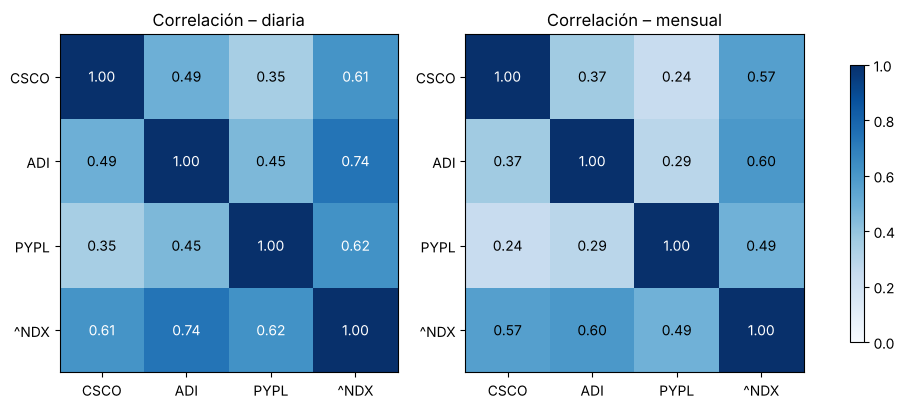

In [6]:
acc = ["CSCO", "ADI", "PYPL"]                            # solo las acciones entran a Markowitz

cov_d = r_d[acc].cov() * 252                             # Σ anual a partir de datos diarios
cov_m = r_m[acc].cov() * 12                              # Σ anual a partir de datos mensuales (comparación)
corr_d = r_d[activos].corr()                             # correlaciones diarias (incluye ^NDX)
corr_m = r_m[activos].corr()                             # correlaciones mensuales

cov_d.to_csv(PROC / "cov_anual_diaria.csv")              # insumo del Punto 3
cov_m.to_csv(PROC / "cov_anual_mensual.csv")             # insumo del Punto 4 (VaR mensual)
corr_d.to_csv(PROC / "corr_diaria.csv")

print(f"{'=' * 70}\nMATRIZ DE VARIANZAS-COVARIANZAS ANUAL (datos diarios × 252)")
display(cov_d.style.format("{:.4f}"))
print(f"{'=' * 70}\nMATRIZ DE VARIANZAS-COVARIANZAS ANUAL (datos mensuales × 12)")
display(cov_m.style.format("{:.4f}"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))          # dos mapas de calor lado a lado
for a, (titulo, c) in zip(ax, [("Correlación – diaria", corr_d), ("Correlación – mensual", corr_m)]):
    im = a.imshow(c, cmap="Blues", vmin=0, vmax=1)        # color según el valor de ρ
    a.set_xticks(range(len(c)), c.columns); a.set_yticks(range(len(c)), c.index)
    for i in range(len(c)):
        for j in range(len(c)):
            a.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center",
                   color="white" if c.iloc[i, j] > 0.6 else "black")   # escribe ρ en cada celda
    a.set_title(titulo)
fig.colorbar(im, ax=ax, shrink=0.8); plt.show()

### **Interpretación de los resultados**

**Retorno y riesgo individual.** En los últimos 10 años ADI fue la acción de mayor retorno anual (22.91 %), pero más volátil que CSCO (33.33 % frente a 26.67 %). Por su lado PYPL tuvo el retorno más bajo (3.31 %, inferior a la tasa libre de riesgo de 4.929 %) con la mayor volatilidad (39.73 %). El Nasdaq-100 obtuvo 19.51 % con solo 22.89 % de volatilidad, una mejor relación retorno/riesgo que cualquiera de las tres acciones por separado, a esto se le llama el efecto de la diversificación, si se hubiera invertido lo mejor sería seleccionar un ETF que replice el índice.

**Por qué la volatilidad diaria anualizada es mayor que la mensual?** Para las tres acciones y el índice, la volatilidad anualizada con datos diarios supera a la mensual entre 10 % y 20 % (ADI: 33.33 % frente a 27.99 %), aunque el retorno anual es casi idéntico. La regla de √k supone que los retornos son independientes entre sí. En la práctica, parte de los movimientos diarios son ruido de corto plazo y ese ruido infla la volatilidad diaria. Ninguna de las dos estimaciones es incorrecta: miden el riesgo a distinta medida del tiempo exigida. Por eso medimos cada una para que conecte con cada punto del laboratorio y se use la frecuencia correcta.

**Matriz de correlaciones.** Aunque la correlación diaria sea fuerte, ninguna correlación entre las acciones se acerca a 1:

| Par | ρ diaria | ρ mensual |
|---|---:|---:|
| CSCO – ADI | 0.49 | 0.37 |
| CSCO – PYPL | 0.35 | 0.24 |
| ADI – PYPL | 0.45 | 0.29 |

Esto confirma lo planteado anteriormente: al tener negocios distintos (redes, chips, pagos), las acciones no se mueven igual y combinarlas reduce el riesgo del portafolio.

Algo interesante a mencionar de como se comporta el mercado es que con datos diarios las correlaciones suben gracias a que el corto plazo las tres acciones reaccionan juntas a las noticias del mercado, del día a día, mientras que en periodos de tiempos mensuales cada una se relacionan más con sus fundamentales.

**Relación con el mercado.** La correlación con el ^NDX es de 0.74 para ADI, 0.62 para PYPL y 0.61 para CSCO. ADI es la que más se correlaciona con el índice, además de ser la segunda más volátil y la que tiene mayor retorno, por lo que, tendrá la beta más alta y será la que más aumente el número de contratos de futuros necesarios para la cobertura.

## Punto 3 – Portafolio óptimo de Markowitz: GMV y Máximo Sharpe (R3 – 7 %)

In [7]:
from scipy.optimize import minimize

rf = 0.04929                                       # ^TNX al 30/10/2026
CAPITAL = 35_000_000                               # USD a invertir
mu = np.exp(r_d[acc].mean() * 252) - 1             # retornos anuales esperados (2.1, diaria)
S = cov_d.values                                   # matriz Σ anual (2.2, diaria × 252)
cotas = [(0.15, 0.45)] * len(acc)                  # peso mínimo 15 % y máximo 45 % por acción
restr = {"type": "eq", "fun": lambda w: w.sum() - 1}   # la suma de pesos debe ser 100 %
w0 = np.repeat(1 / len(acc), len(acc))
opt = {"ftol": 1e-12, "maxiter": 1000}               # tolerancia estricta: mismo resultado en cualquier computador             # punto de partida: pesos iguales (semilla)

def ret_p(w): return w @ mu.values                 # E(rp) = Σ wi·μi
def vol_p(w): return np.sqrt(w @ S @ w)            # σp = √(wᵀ Σ w)
def sharpe(w): return (ret_p(w) - rf) / vol_p(w)   # Sp = (E(rp) − rf) / σp

gmv = minimize(vol_p, w0, method="SLSQP", bounds=cotas, constraints=restr, options=opt)               # mínima σp
msr = minimize(lambda w: -sharpe(w), w0, method="SLSQP", bounds=cotas, constraints=restr, options=opt) # máximo Sp
assert gmv.success and msr.success, "La optimización no convergió"

def resumen(w):                                    # arma la ficha de un portafolio
    return pd.Series({**{f"Peso {a}": x for a, x in zip(acc, w)},
                      **{f"Monto {a} (USD)": x * CAPITAL for a, x in zip(acc, w)},
                      "Monto total (USD)": w.sum() * CAPITAL,
                      "Retorno esperado": ret_p(w), "Desv. estándar": vol_p(w), "Sharpe": sharpe(w)})

port = pd.DataFrame({"GMV": resumen(gmv.x), "Máx. Sharpe": resumen(msr.x)})
port.to_csv(PROC / "portafolios_markowitz.csv")    # insumo de los Puntos 4 a 12

def fmt_fila(fila, v):                             # formato según el tipo de fila
    if fila.startswith("Monto"): return f"{v:,.2f}"                       # USD: 15,750,000.00
    if fila == "Sharpe": return f"{v:.4f}"
    return f"{v:.2%}"                                                     # pesos, retorno y riesgo
tabla_p3 = pd.DataFrame({c: [fmt_fila(i, port.at[i, c]) for i in port.index] for c in port},
                        index=port.index)
print(f"{'=' * 80}\nPORTAFOLIOS ÓPTIMOS · r_f = {rf:.3%} · capital USD {CAPITAL:,.0f} · pesos 15% – 45%")
display(tabla_p3)

PORTAFOLIOS ÓPTIMOS · r_f = 4.929% · capital USD 35,000,000 · pesos 15% – 45%


,GMV,Máx. Sharpe
Peso CSCO,45.00%,40.00%
Peso ADI,33.97%,45.00%
Peso PYPL,21.03%,15.00%
Monto CSCO (USD),"15,750,000.00","14,000,000.00"
Monto ADI (USD),"11,889,424.90","15,750,000.00"
Monto PYPL (USD),"7,360,575.10","5,250,000.00"
Monto total (USD),"35,000,000.00","35,000,000.00"
Retorno esperado,15.88%,17.39%
Desv. estándar,25.12%,25.63%
Sharpe,0.4359,0.4860


### **Portafolios óptimos**
Para efectos del ejercicio, optamos por tener una restricción de pesos entre 15 % y 45 %, el portafolio de mínima varianza (GMV) asigna 45.00 % a CSCO, 33.97 % a ADI y 21.03 % a PYPL, con una volatilidad de 25.12 % y un retorno esperado de 15.88 %. El de Máximo Sharpe asigna 40.00 % a CSCO, 45.00 % a ADI y 15.00 % a PYPL, con 17.39 % de retorno, 25.63 % de volatilidad y un Sharpe de 0.4860.

Las restricciones se activan en ambos casos: CSCO queda en el techo del portafolio de mínima varianza y ADI en el techo y PYPL en el piso del Máximo Sharpe. Sin restricciones, el Máximo Sharpe excluiría a PYPL, porque su retorno histórico (3.31 %) es inferior a la tasa libre de riesgo.

La acción de PYPL se queda por la diversificación, reduce el riesgo frente al promedio ponderado de las volatilidades individuales: ambos portafolios son menos volátiles que CSCO, la acción menos riesgosa.

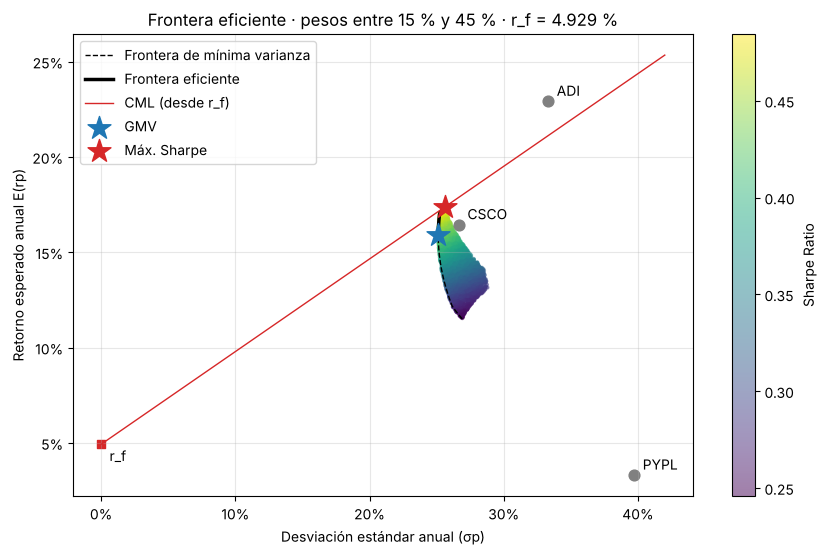

Retorno factible con las restricciones: 11.50% – 17.39%


In [8]:
# Rango de retornos alcanzables con las restricciones de 15 %–45 %
r_lo = minimize(ret_p, w0, method="SLSQP", bounds=cotas, constraints=restr).fun            # retorno mínimo
r_hi = -minimize(lambda w: -ret_p(w), w0, method="SLSQP", bounds=cotas, constraints=restr).fun  # retorno máximo

frontera = []                                                    # (σ, E(r)) de cada punto de la curva
for R in np.linspace(r_lo, r_hi, 60):                            # 60 retornos objetivo
    c = [restr, {"type": "eq", "fun": lambda w, R=R: ret_p(w) - R}]   # exige E(rp) = R
    res = minimize(vol_p, w0, method="SLSQP", bounds=cotas, constraints=c)
    if res.success: frontera.append((res.fun, R))
frontera = np.array(frontera)
eficiente = frontera[frontera[:, 1] >= ret_p(gmv.x) - 1e-9]      # tramo por encima del GMV

rng = np.random.default_rng(42)                                  # semilla: resultado reproducible
W = rng.dirichlet(np.ones(len(acc)), 30_000)                     # pesos aleatorios que suman 1
W = W[((W >= 0.15) & (W <= 0.45)).all(axis=1)]                   # deja solo los que cumplen los límites
nube_r = W @ mu.values                                           # retorno de cada portafolio aleatorio
nube_s = np.sqrt(np.einsum("ij,jk,ik->i", W, S, W))              # riesgo de cada portafolio aleatorio

fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(nube_s, nube_r, c=(nube_r - rf) / nube_s, cmap="viridis", s=4, alpha=0.5)
fig.colorbar(sc, label="Sharpe Ratio")
ax.plot(frontera[:, 0], frontera[:, 1], "k--", lw=1, label="Frontera de mínima varianza")
ax.plot(eficiente[:, 0], eficiente[:, 1], "k-", lw=2.5, label="Frontera eficiente")
x_cml = np.linspace(0, 0.42, 50)
ax.plot(x_cml, rf + sharpe(msr.x) * x_cml, color="tab:red", lw=1, label="CML (desde r_f)")
for a in acc:                                                    # acciones individuales
    ax.scatter(np.sqrt(cov_d.loc[a, a]), mu[a], marker="o", s=60, color="grey")
    ax.annotate(a, (np.sqrt(cov_d.loc[a, a]), mu[a]), xytext=(6, 4), textcoords="offset points")
ax.scatter(vol_p(gmv.x), ret_p(gmv.x), marker="*", s=300, color="tab:blue", label="GMV", zorder=5)
ax.scatter(vol_p(msr.x), ret_p(msr.x), marker="*", s=300, color="tab:red", label="Máx. Sharpe", zorder=5)
ax.scatter(0, rf, marker="s", color="tab:red"); ax.annotate("r_f", (0, rf), xytext=(6, -12), textcoords="offset points")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Desviación estándar anual (σp)"); ax.set_ylabel("Retorno esperado anual E(rp)")
ax.set_title("Frontera eficiente · pesos entre 15 % y 45 % · r_f = 4.929 %")
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
fig.savefig("../outputs/figures/frontera_eficiente.png", dpi=150, bbox_inches="tight")  # para el informe APA
plt.show()
print(f"Retorno factible con las restricciones: {r_lo:.2%} – {r_hi:.2%}")

### **Portafolio definitivo: Máximo Sharpe** (CSCO 40 % · ADI 45 % · PYPL 15 %).

Se eligió el portafolio de Máximo Sharpe sobre el de mínima varianza por estas razones:

| Criterio | GMV | Máx. Sharpe |
| :--- | :--- | :--- |
| **Retorno esperado** | 15.88 % (≈ USD 5.56 M/año) | 17.39 % (≈ USD 6.09 M/año) |
| **Volatilidad** | 25.12 % | 25.63 % (+0.51 pp) |
| **Sharpe** | 0.4359 | 0.4860 |
| **Concentración** | CSCO en el techo (45 %) | ADI en el techo (45 %), PYPL en el piso (15 %) |
| **Objetivo del gerente (4 años con cobertura)** | Prioriza el menor riesgo | La cobertura con futuros ya reduce el riesgo de mercado, así que conviene elegir el portafolio más eficiente (mejor Sharpe) |

*Limitación:* el portafolio depende de retornos esperados históricos, la restricción de 15 %–45 % reduce su Sharpe frente al óptimo sin límites (0.57), a cambio de evitar concentrar el capital.

## Punto 4 – VaR mensual al 1 % y 5 % (R5 – 8 %)

VaR MENSUAL PARAMÉTRICO · Máximo Sharpe · V0 = USD 35,000,000
μ mensual = 1.3182% · σ mensual = 6.0200% · ganancia esperada del mes ≈ USD 464,433


,α (VaR al),z,Retorno crítico (log),VaR (%),VaR (USD)
VaR 95%,5%,1.6449,-8.5837%,8.23%,"2,878,978.61"
VaR 99%,1%,2.3263,-12.6863%,11.91%,"4,170,100.79"


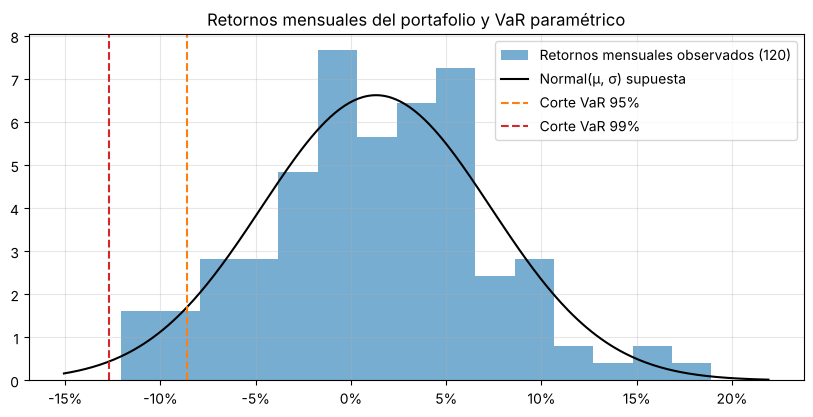

In [9]:
from scipy.stats import norm

w_opt = msr.x                                      # pesos del Máximo Sharpe (40 / 45 / 15)
V0 = CAPITAL                                       # valor inicial: USD 35,000,000
rp_m = r_m[acc] @ w_opt                            # retorno log mensual del portafolio (120 meses)
mu_m, sig_m = rp_m.mean(), rp_m.std()              # μ y σ mensuales del portafolio

filas = {}
for c in [0.95, 0.99]:                             # niveles de confianza
    z = norm.ppf(c)                                # 1.645 y 2.326
    r_crit = mu_m - z * sig_m                      # retorno crítico: peor caso al c %
    filas[f"VaR {c:.0%}"] = {
        "α (VaR al)": 1 - c, "z": z, "Retorno crítico (log)": r_crit,
        "VaR (%)": 1 - np.exp(r_crit),             # pérdida porcentual: 1 − e^(r*)
        "VaR (USD)": V0 * (1 - np.exp(r_crit)),    # pérdida en dólares sobre USD 35 M
    }
var_tab = pd.DataFrame(filas).T
var_tab.to_csv(PROC / "var_mensual.csv")           # insumo de los Puntos 10 y 11

print(f"{'=' * 70}\nVaR MENSUAL PARAMÉTRICO · Máximo Sharpe · V0 = USD {V0:,.0f}")
print(f"μ mensual = {mu_m:.4%} · σ mensual = {sig_m:.4%} · ganancia esperada del mes ≈ USD {V0*(np.exp(mu_m)-1):,.0f}")
display(var_tab.style.format({"α (VaR al)": "{:.0%}", "z": "{:.4f}", "Retorno crítico (log)": "{:.4%}",
                              "VaR (%)": "{:.2%}", "VaR (USD)": "{:,.2f}"}))

fig, ax = plt.subplots(figsize=(10, 4.5))          # distribución de retornos mensuales y cortes del VaR
ax.hist(rp_m, bins=15, density=True, alpha=0.6, label="Retornos mensuales observados (120)")
x = np.linspace(rp_m.min() - 0.03, rp_m.max() + 0.03, 300)
ax.plot(x, norm.pdf(x, mu_m, sig_m), "k-", label="Normal(μ, σ) supuesta")
for c, col in [(0.95, "tab:orange"), (0.99, "tab:red")]:
    ax.axvline(filas[f"VaR {c:.0%}"]["Retorno crítico (log)"], color=col, ls="--", label=f"Corte VaR {c:.0%}")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Retornos mensuales del portafolio y VaR paramétrico"); ax.legend(); ax.grid(alpha=0.3)
fig.savefig("../outputs/figures/var_mensual.png", dpi=150, bbox_inches="tight"); plt.show()

### **VaR mensual:** 
El portafolio de Máximo Sharpe (USD 35,000,000) tiene un retorno esperado mensual de 1.32%  (≈ USD 464,433) y una volatilidad mensual de 6.02%. Teniendo en cuenta que su distribución se asemeja a una normal:

- **VaR 95 % (al 5 %): 8.23 % ≈ USD 2,878,979.** En 19 de cada 20 meses la pérdida no debería superar esta cifra, en el mes restante podría ser mayor.
- **VaR 99 % (al 1 %): 11.91 % ≈ USD 4,170,101.** Es la pérdida de un mes extremo, que ocurriría 1 vez cada 100 meses.

### **Cuánto del VaR podemos eliminar con la cobertura?** 

Descompusimos el riesgo del portafolio con el modelo de mercado: 

- $r_p = α + β·r_{NDX} + ε$. Como el componente específico $ε$ no está correlacionado con el índice, la varianza total se divide en dos partes: 
    
    - $σ_p^2 = β^2σ^2_{NDX} + σ^2_ε.$ 
    
    - El coeficiente de determinación $R² = ρ(r_p, r_{NDX})^2$ mide qué fracción de la varianza explica el Nasdaq-100.

In [10]:
r_ndx_m = r_m["^NDX"]                                   # retornos log mensuales del Nasdaq-100

beta_m = rp_m.cov(r_ndx_m) / r_ndx_m.var()             # β = Cov(rp, rm) / Var(rm) (preliminar, mensual)
R2 = rp_m.corr(r_ndx_m) ** 2                            # R² = ρ²: fracción de la varianza explicada por el índice
sig_sis = np.sqrt(R2) * sig_m                           # σ sistemática (= β · σ_NDX)
sig_esp = np.sqrt(1 - R2) * sig_m                       # σ específica (σ_ε): lo que la cobertura no elimina

descomp = pd.DataFrame({
    "Varianza mensual": [sig_m**2, sig_sis**2, sig_esp**2],
    "% de la varianza": [1, R2, 1 - R2],
    "σ mensual": [sig_m, sig_sis, sig_esp],
}, index=["Total del portafolio", "Sistemática (cubrible con futuros)", "Específica (no cubrible)"])
print(f"{'=' * 70}\nDESCOMPOSICIÓN DEL RIESGO MENSUAL · β mensual = {beta_m:.4f} · R² = {R2:.4f}")
display(descomp.style.format({"Varianza mensual": "{:.6f}", "% de la varianza": "{:.2%}", "σ mensual": "{:.4%}"}))

comp = {}                                               # VaR sin cobertura vs. con cobertura ideal
for c in [0.95, 0.99]:
    z = norm.ppf(c)
    var_sin = 1 - np.exp(mu_m - z * sig_m)              # con todo el riesgo
    var_con = 1 - np.exp(mu_m - z * sig_esp)            # solo con riesgo específico (cobertura perfecta)
    comp[f"VaR {c:.0%}"] = {"Sin cobertura (%)": var_sin, "Sin cobertura (USD)": V0 * var_sin,
                            "Cubierto (%)": var_con, "Cubierto (USD)": V0 * var_con,
                            "Reducción (USD)": V0 * (var_sin - var_con), "Reducción (%)": 1 - var_con / var_sin}
comp = pd.DataFrame(comp).T
comp.to_csv(PROC / "var_cubierto_vs_sin.csv")
print(f"{'=' * 70}\nVaR MENSUAL: SIN COBERTURA vs. COBERTURA IDEAL DEL RIESGO SISTEMÁTICO")
display(comp.style.format("{:,.2f}", subset=["Sin cobertura (USD)", "Cubierto (USD)", "Reducción (USD)"])
            .format("{:.2%}", subset=["Sin cobertura (%)", "Cubierto (%)", "Reducción (%)"]))
print(f"Exposición sistemática a cubrir ≈ β × V0 => {beta_m:.4f} × {V0:,.0f} = USD {beta_m * V0:,.2f}")

DESCOMPOSICIÓN DEL RIESGO MENSUAL · β mensual = 0.8206 · R² = 0.5603


,Varianza mensual,% de la varianza,σ mensual
Total del portafolio,0.003624,100.00%,6.0200%
Sistemática (cubrible con futuros),0.002030,56.03%,4.5060%
Específica (no cubrible),0.001594,43.97%,3.9920%


VaR MENSUAL: SIN COBERTURA vs. COBERTURA IDEAL DEL RIESGO SISTEMÁTICO


,Sin cobertura (%),Sin cobertura (USD),Cubierto (%),Cubierto (USD),Reducción (USD),Reducción (%)
VaR 95%,8.23%,"2,878,978.61",5.11%,"1,789,466.95","1,089,511.66",37.84%
VaR 99%,11.91%,"4,170,100.79",7.66%,"2,680,797.33","1,489,303.46",35.71%


Exposición sistemática a cubrir ≈ β × V0 => 0.8206 × 35,000,000 = USD 28,720,153.35


**Relación con la cobertura:** Con los 120 retornos mensuales, la correlación entre el portafolio y el ^NDX es 0.75, por lo que **R² = 0.56**: el 56 % de la varianza del portafolio es riesgo **sistemático**, que se mueve con el índice, esa es la parte que se puede cubrir con una posición en futuros sobre el Nasdaq-100. El 44 % restante es riesgo **específico** de las tres empresas (por ejemplo, la caída de PayPal en febrero de 2026), que un futuro sobre el índice no puede cubrir.

Esto define el **monto a cubrir**: nunca será la inversión total que en nuestro caso son los USD 35 millones completos, sino la exposición equivalente al índice, $0.82 \times 35$ M ≈ USD $28.7$ millones. Sobre esta base se calcula el número de contratos.

En la práctica esta beta es preliminar ya que en el siguiente punto esta beta se calcula con datos diarios como se estableció en unos puntos atrás. Con datos diarios la beta del protafolio sale más alta, ya que, las correlaciones diarias son mayores que las mensuales y se dió su respectiva explicación del por qué son mucho mayores.

## Punto 5 – Betas CAPM y beta del portafolio (R6 – 8 %)

**Beta:** cuánto se mueve la acción cuando el mercado se mueve 1%:

$β_i = Cov(r_i, r_m) / Var(r_m)$

In [11]:
from scipy.stats import linregress

mkt = "^NDX"
E_rm = np.exp(r_d[mkt].mean() * 252) - 1               # retorno anual esperado del mercado (2.1): 19.51 %

filas = {}
for a in acc:
    reg = linregress(r_d[mkt], r_d[a])                 # regresión diaria: r_a = α + β · r_NDX + ε
    beta_mens = r_m[a].cov(r_m[mkt]) / r_m[mkt].var()  # β con datos mensuales (solo comparación)
    filas[a] = {
        "β diaria": reg.slope, "Error est. β": reg.stderr, "t de β": reg.slope / reg.stderr,
        "R²": reg.rvalue ** 2,                         # fracción del riesgo de la acción explicada por el mercado
        "α anual": reg.intercept * 252,                # retorno no explicado por el mercado (anualizado)
        "β mensual (comparación)": beta_mens,
        "Peso (Máx. Sharpe)": w_opt[acc.index(a)],
        "E(r) CAPM": rf + reg.slope * (E_rm - rf),     # SML: rf + β (E(rm) − rf)
        "E(r) histórico": mu[a],                       # retorno anual del Punto 2
    }
betas = pd.DataFrame(filas).T

beta_p = (betas["Peso (Máx. Sharpe)"] * betas["β diaria"]).sum()                 # βp = Σ wi · βi
beta_p_m = (betas["Peso (Máx. Sharpe)"] * betas["β mensual (comparación)"]).sum()
beta_p_reg = linregress(r_d[mkt], r_d[acc] @ w_opt).slope                        # verificación: regresión directa
betas.loc["Portafolio"] = {"β diaria": beta_p, "β mensual (comparación)": beta_p_m, "Peso (Máx. Sharpe)": 1,
                           "E(r) CAPM": rf + beta_p * (E_rm - rf), "E(r) histórico": ret_p(w_opt)}
betas.to_csv(PROC / "betas_capm.csv")                  # insumo del Punto 6

print(f"{'=' * 80}\nBETAS CAPM vs ^NDX · datos diarios 01/11/2016 – 30/10/2026 · E(rm) = {E_rm:.2%} · rf = {rf:.3%}")
display(betas.style.format("{:.4f}", subset=["β diaria", "Error est. β", "β mensual (comparación)"], na_rep="–")
             .format("{:.1f}", subset=["t de β"], na_rep="–")
             .format("{:.2%}", subset=["R²", "α anual", "Peso (Máx. Sharpe)", "E(r) CAPM", "E(r) histórico"], na_rep="–"))
print(f"βp = Σ wi·βi = {beta_p:.4f}  ·  verificación por regresión directa = {beta_p_reg:.4f}")

BETAS CAPM vs ^NDX · datos diarios 01/11/2016 – 30/10/2026 · E(rm) = 19.51% · rf = 4.929%


,β diaria,Error est. β,t de β,R²,α anual,β mensual (comparación),Peso (Máx. Sharpe),E(r) CAPM,E(r) histórico
CSCO,0.7149,0.0184,38.9,37.64%,2.49%,0.7173,40.00%,15.35%,16.44%
ADI,1.0707,0.0197,54.4,54.07%,1.55%,0.8774,45.00%,20.54%,22.91%
PYPL,1.0839,0.0271,40.1,38.99%,-16.06%,0.9258,15.00%,20.73%,3.31%
Portafolio,0.9304,–,–,–,–,0.8206,100.00%,18.49%,17.39%


βp = Σ wi·βi = 0.9304  ·  verificación por regresión directa = 0.9304


### **Interpretación de las betas**

**CSCO (β = 0.71)** es una acción que amortigua los movimientos del mercado. **ADI (β = 1.07)** y **PYPL (β = 1.08)** son un poco más agresivas, ya que, amplifican sus movimientos por su exposición al ciclo de semiconductores y al consumo de pagos y créditos.

**Beta del portafolio y exposición sistemática.** Con los pesos del Máximo Sharpe, $β_p = 0.40(0.71) + 0.45(1.07) + 0.15(1.08) =$ **0.93**. El portafolio de USD 35 millones equivale a una exposición de aproximadamente USD 32.56 millones frente al Nasdaq-100: si el índice cae 10 %, el portafolio pierde en promedio 9.30 % (≈ USD 3.26 millones). Esta es lo que justamente podemos cubrir con futuros.

**CAPM.** Con $E(r_m) = 19.51\%$ y $r_f = 4.929 \%$, CSCO (α = +2.49 %) y ADI (α = +1.55 %) superaron el retorno exigido por el CAPM, mientras que PYPL quedó muy por debajo, confirmando el deterioro sostenido explicado en el análisis fundamental.

*Nota:* con datos mensuales la beta del portafolio es 0.82. La diferencia se explica por la mayor movilidad diaria observada en el mercado, la beta que se usará para el número de contratos se define en el siguiente bloque.